In [1]:
!pip install xarray

In [2]:
import xarray as xr

ds = xr.open_dataset(r"D:\Documents\JUKUT\data\1cb3727dd35f7b54bfe92f8f369b7251.grib", engine="cfgrib")
print(ds)
print("variable:", list(ds.data_vars))
print("date:", ds.time.min().values, "->", ds.time.max().values)
print("latitude:", float(ds.latitude.min()), float(ds.latitude.max()))
print("longitude:", float(ds.longitude.min()), float(ds.longitude.max()))

<xarray.Dataset> Size: 12MB
Dimensions:     (time: 1528, values: 968)
Coordinates:
  * time        (time) datetime64[ns] 12kB 2021-04-01 2021-04-02 ... 2026-08-31
    valid_time  (time) datetime64[ns] 12kB ...
    latitude    (values) float64 8kB ...
    longitude   (values) float64 8kB ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
Dimensions without coordinates: values
Data variables:
    drtcode     (time, values) float32 6MB ...
    fwinx       (time, values) float32 6MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-15T21:21 GRIB to CDM+CF via cfgrib-0.9.1...
variable: ['drtcode', 'fwinx']
date: 2021-04-01T00:00:00.000000000 -> 2026-08-31T00:00:00.000000000
lati

In [3]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
labels = pd.read_csv(r"D:\Documents\JUKUT\labels\labels_pilot.csv", parse_dates=["date"])
labels = labels[labels.date.between(ds.time.min().values, ds.time.max().values)]

In [5]:
# Setup — packages for the whole notebook (restart the kernel after the first install)
%pip install -q cfgrib eccodes scipy scikit-learn lightgbm matplotlib geopandas cdsapi joblib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import json, shutil
from pathlib import Path

import cdsapi, joblib, shapely
import geopandas as gpd, lightgbm as lgb, matplotlib.pyplot as plt
import numpy as np, pandas as pd, xarray as xr
from scipy.spatial import cKDTree
from shapely.geometry import box
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path(r"D:\Documents\JUKUT")
DATA = ROOT / "data"
LON0, LAT0, LON1, LAT1, CELL = 27.2, 36.0, 32.4, 37.7, 0.05   # same grid as 02_build_labels.py

# Tahap 1 — Pengumpulan & penyelarasan data
Semua sumber diproyeksikan ke grid 0,05° (~5 km) dan resolusi harian: FWI + sub-indeks (EWDS), label hotspot VIIRS (`02_build_labels.py`), dan OSM.

In [7]:
# FWI sub-indices from EWDS (needs ~/.cdsapirc with url https://ewds.climate.copernicus.eu/api).
# One request per year keeps each request under the EWDS size limit; existing files are skipped.
SUB_VARS = ["fine_fuel_moisture_code", "duff_moisture_code", "initial_fire_spread_index", "build_up_index"]
MONTHS = {y: range(4, 13) for y in range(2021, 2026)} | {2026: range(4, 9)}   # same span as the FWI file

for year, months in MONTHS.items():
    out = DATA / f"fwi_sub_{year}.grib"
    if out.exists():
        continue
    request = {
        "product_type": "reanalysis", "variable": SUB_VARS, "system_version": ["4_1"],
        "dataset_type": "consolidated_dataset",
        "year": [str(year)], "month": [f"{m:02d}" for m in months], "day": [f"{d:02d}" for d in range(1, 32)],
        "grid": "original_grid", "area": [LAT1, LON0, LAT0, LON1], "data_format": "grib",
    }
    cdsapi.Client().retrieve("cems-fire-historical-v1", request, str(out))
sorted(p.name for p in DATA.glob("fwi_sub_*.grib"))

['fwi_sub_2021.grib',
 'fwi_sub_2022.grib',
 'fwi_sub_2023.grib',
 'fwi_sub_2024.grib',
 'fwi_sub_2025.grib',
 'fwi_sub_2026.grib']

In [8]:
# Land mask = the cells the dashboard draws (schematic coastline, replaceable later)
dash_demo = ROOT / "bizdenbize/dashboard/data.demo.json"
with open(dash_demo if dash_demo.exists() else ROOT / "bizdenbize/dashboard/data.json", encoding="utf-8") as f:
    land_json = json.load(f)["cells"]
land = pd.DataFrame({"ix": land_json["ix"], "iy": land_json["iy"]})
cells = land.copy()
cells["lat_c"] = LAT0 + (cells.iy + 0.5) * CELL
cells["lon_c"] = LON0 + (cells.ix + 0.5) * CELL

# FWI + DC: nearest *non-sea* point of the ~0.28° grid for every 0.05° cell
fwi, dc = ds["fwinx"].values, ds["drtcode"].values
valid = ~np.isnan(fwi).all(axis=0)
pts = np.column_stack([ds.latitude.values, ds.longitude.values])
_, k = cKDTree(pts[valid]).query(cells[["lat_c", "lon_c"]].values)
cells["fwi_idx"] = np.flatnonzero(valid)[k]

# FFMC, DMC, ISI, BUI: same grid but cut to the pilot bbox, so it has its own point index
sub = xr.concat([xr.open_dataset(p, engine="cfgrib", backend_kwargs={"indexpath": ""})
                 for p in sorted(DATA.glob("fwi_sub_*.grib"))], dim="time")
SUB = {"ffmcode": "ffmc", "dufmcode": "dmc", "infsinx": "isi", "fbupinx": "bui"}
sub_vals = {v: sub[k].values for k, v in SUB.items()}
sub_valid = ~np.isnan(sub_vals["ffmc"]).all(axis=0)
sub_pts = np.column_stack([sub.latitude.values, sub.longitude.values])
_, k = cKDTree(sub_pts[sub_valid]).query(cells[["lat_c", "lon_c"]].values)
cells["sub_idx"] = np.flatnonzero(sub_valid)[k]
print("sel darat:", len(cells), "| titik FWI dipakai:", cells.fwi_idx.nunique())

sel darat: 2270 | titik FWI dipakai: 86


# Tahap 2 — Feature engineering
Satu baris = satu sel × satu hari, dengan tiga grup fitur:
- **cuaca** (dinamis): FWI + FFMC/DMC/DC/ISI/BUI, tren 3–7 hari, hari dalam tahun
- **manusia** (statis, OSM): jarak ke jalan / permukiman / lahan pertanian, kepadatan jalan
- **histori**: laju kebakaran sel & tetangganya di tahun training (tanpa leakage)

In [9]:
# Dynamic weather features per FWI point; rolling windows run per year so they never bridge the Dec->Apr gap.
# Windows use shift(1): "the days before today".
times = pd.DatetimeIndex(ds.time.values)
used = np.unique(cells.fwi_idx)
w = pd.DataFrame({"fwi_idx": np.repeat(used, len(times)), "date": np.tile(times, len(used)),
                  "fwi": fwi[:, used].T.ravel(), "dc": dc[:, used].T.ravel()})
g = w.groupby(["fwi_idx", w.date.dt.year])["fwi"]
w["fwi_mean3"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
w["fwi_mean7"] = g.transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
w["fwi_max7"] = g.transform(lambda s: s.shift(1).rolling(7, min_periods=1).max())
w["dc_change7"] = w.dc - w.groupby(["fwi_idx", w.date.dt.year])["dc"].shift(7)

sub_times = pd.DatetimeIndex(sub.time.values)
sused = np.unique(cells.sub_idx)
s = pd.DataFrame({"sub_idx": np.repeat(sused, len(sub_times)), "date": np.tile(sub_times, len(sused)),
                  **{v: a[:, sused].T.ravel() for v, a in sub_vals.items()}})

df = (labels.merge(land, on=["ix", "iy"]).merge(cells, on=["ix", "iy"])
      .merge(w, on=["fwi_idx", "date"]).merge(s, on=["sub_idx", "date"]))
df = df.dropna(subset=["fwi", "ffmc"])
df["doy"] = df.date.dt.day_of_year
df["year"] = df.date.dt.year
print("baris sel-hari:", len(df), "| positif:", df.y.sum())
df.groupby("year").y.agg(["size", "sum"])

baris sel-hari: 3468560 | positif: 3272


,size,sum
year,,
2021,624250,927
2022,624250,417
2023,624250,399
2024,624250,632
2025,624250,651
2026,347310,246


In [10]:
# OpenStreetMap layers from the Geofabrik Türkiye extract (the public Overpass API was overloaded).
# Download once (~1.5 GB) into data/: https://download.geofabrik.de/europe/turkey-latest-free.shp.zip
ZIP = DATA / "turkey-latest-free.shp.zip"
PAD = 0.3   # margin around the bbox so edge cells still find their nearest road
OSM_LAYERS = {
    "roads": ("gis_osm_roads_free_1.shp",
              ["motorway", "trunk", "primary", "secondary", "tertiary", "unclassified"]),
    "settlements": ("gis_osm_places_free_1.shp", ["city", "town", "village", "hamlet"]),
    "farmland": ("gis_osm_landuse_a_free_1.shp", ["farmland", "orchard"]),
}
for name, (shp, classes) in OSM_LAYERS.items():
    path = DATA / f"osm_{name}.gpkg"
    if not path.exists():
        where = "fclass IN (" + ",".join(f"'{c}'" for c in classes) + ")"
        gpd.read_file(f"zip://{ZIP}!{shp}", bbox=(LON0 - PAD, LAT0 - PAD, LON1 + PAD, LAT1 + PAD),
                      where=where, columns=["fclass"]).to_file(path, driver="GPKG")
    print(name, len(gpd.read_file(path)), "fitur")

roads 48458 fitur
settlements 2921 fitur
farmland 7769 fitur


In [11]:
# Static-human features per cell (EPSG:3035 = metres): distance to road / settlement / farmland,
# and km of road inside the cell. Cached to data/static_human.csv.
STATIC_PATH = DATA / "static_human.csv"
if not STATIC_PATH.exists():
    grid = gpd.GeoDataFrame(
        cells[["ix", "iy"]],
        geometry=[box(LON0 + x * CELL, LAT0 + y * CELL, LON0 + (x + 1) * CELL, LAT0 + (y + 1) * CELL)
                  for x, y in zip(cells.ix, cells.iy)],
        crs=4326).to_crs(3035)
    centres = grid.set_geometry(grid.centroid)
    static = cells[["ix", "iy"]].copy()
    for name, col in [("roads", "dist_road_km"), ("settlements", "dist_set_km"), ("farmland", "dist_farm_km")]:
        layer = gpd.read_file(DATA / f"osm_{name}.gpkg").to_crs(3035)
        if name == "settlements":
            layer["geometry"] = layer.representative_point()
        j = gpd.sjoin_nearest(centres, layer[["geometry"]], distance_col="d")
        static[col] = (j.groupby(level=0)["d"].min() / 1000).round(2).values
    roads = gpd.read_file(DATA / "osm_roads.gpkg").to_crs(3035)
    pieces = gpd.overlay(roads[["geometry"]], grid, how="intersection", keep_geom_type=True)
    road_len = (pieces.length / 1000).groupby([pieces.ix, pieces.iy]).sum().rename("road_km_per_cell")
    static = static.merge(road_len.reset_index(), on=["ix", "iy"], how="left").fillna({"road_km_per_cell": 0})
    static.to_csv(STATIC_PATH, index=False)
static = pd.read_csv(STATIC_PATH)
static.describe().T[["50%", "max"]]

,50%,max
ix,54.000000,103.000000
iy,23.000000,33.000000
dist_road_km,0.870000,12.130000
dist_set_km,2.630000,17.160000
dist_farm_km,6.225000,24.160000
road_km_per_cell,10.332137,163.043512


### Fitur statis-lingkungan (belum ada)
Slot untuk **lereng** (SRTM 30 m, opentopography.org) dan **tutupan lahan** (CORINE 2018 — hutan *Pinus brutia* vs lahan terbuka). Setelah diunduh: hitung per sel seperti `static_human.csv`, simpan `data/static_env.csv`, dan tambahkan grup `"lingkungan"` ke `GROUPS` di sel berikut.

In [12]:
# Fire history per cell — leakage-safe: a training year only sees the *other* training years,
# validation/test years see all training years
HISTORY = ["hist_cell", "hist_nb"]


def history_from(df, years):
    """Fire-days per year in each cell and its 3x3 neighbourhood, counted over `years`."""
    pos = df[df.year.isin(years) & (df.y == 1)].groupby(["ix", "iy"]).size()
    h = pos.rename("hist_cell").reset_index()
    nb = pd.concat([h.assign(ix=h.ix + dx, iy=h.iy + dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1)])
    nb = nb.groupby(["ix", "iy"]).hist_cell.sum().rename("hist_nb").reset_index()
    out = h.merge(nb, on=["ix", "iy"], how="outer").fillna(0)
    out[HISTORY] = out[HISTORY] / len(years)
    return out


def add_history(df, train_years):
    parts = []
    for year, part in df.groupby("year"):
        h = history_from(df, [y for y in train_years if y != year])
        parts.append(part.drop(columns=HISTORY, errors="ignore").merge(h, on=["ix", "iy"], how="left"))
    out = pd.concat(parts, ignore_index=True)
    out[HISTORY] = out[HISTORY].fillna(0)
    return out


WEATHER = ["fwi", "ffmc", "dmc", "dc", "isi", "bui", "fwi_mean3", "fwi_mean7", "fwi_max7", "dc_change7", "doy"]
HUMAN = ["dist_road_km", "dist_set_km", "dist_farm_km", "road_km_per_cell"]
GROUPS = {"cuaca": WEATHER, "manusia": HUMAN, "histori": HISTORY}   # + "lingkungan" once SRTM/CORINE are in
FEATURES = WEATHER + HUMAN + HISTORY
df = df.drop(columns=HUMAN, errors="ignore").merge(static, on=["ix", "iy"])

# Tahap 3 — Model prediksi
- **Utama**: LightGBM. **Baseline**: FWI saja dan regresi logistik.
- **Class imbalance** (~0,1% positif): evaluasi dengan PR-AUC / F1, bukan accuracy.
- **Leakage**: split temporal — train 2021–23, validasi 2024, test 2025 — plus **hindcast 2021** (model dilatih 2022–25) untuk menguji bencana Manavgat/Marmaris.

In [13]:
def scores(y, p):
    """PR-AUC, ROC-AUC, best F1, and the share of fires inside the 5% highest-risk cell-days."""
    prec, rec, _ = precision_recall_curve(y, p)
    f1 = (2 * prec * rec / np.clip(prec + rec, 1e-12, None)).max()
    top = p >= np.quantile(p, 0.95)
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "best F1": f1, "api di top 5%": y[top].sum() / y.sum()}


def fit_lgbm(X, y, Xv=None, yv=None, n_estimators=3000, **params):
    m = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.03, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, min_child_samples=200, reg_lambda=1.0,
                           verbose=-1, **params)
    if Xv is None:
        return m.fit(X, y)
    return m.fit(X, y, eval_set=[(Xv, yv)], eval_metric="average_precision",
                 callbacks=[lgb.early_stopping(150, verbose=False)])

In [14]:
# Split A: train 2021-23, validation 2024, test 2025 — tune LightGBM on validation PR-AUC
d = add_history(df, [2021, 2022, 2023])
tr, va = d[d.year <= 2023], d[d.year == 2024]
spw = (tr.y == 0).sum() / tr.y.sum()
print("positif train:", tr.y.sum(), "| neg/pos:", round(spw))

best = None
for leaves in (15, 63):
    for w in (1.0, np.sqrt(spw)):   # no weighting vs sqrt(neg/pos); full neg/pos overfits after a few trees
        m = fit_lgbm(tr[FEATURES], tr.y, va[FEATURES], va.y, num_leaves=leaves, scale_pos_weight=w)
        ap = average_precision_score(va.y, m.predict_proba(va[FEATURES])[:, 1])
        print(f"num_leaves={leaves} scale_pos_weight={w:.0f} trees={m.best_iteration_} val PR-AUC={ap:.4f}")
        if best is None or ap > best[0]:
            best = (ap, leaves, w, m.best_iteration_)
_, LEAVES, SPW_USED, N_IT = best
SPW_SQRT = SPW_USED != 1.0
print("terbaik:", best)

positif train: 1743 | neg/pos: 1073


d:\Documents\JUKUT\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


num_leaves=15 scale_pos_weight=1 trees=276 val PR-AUC=0.0108


d:\Documents\JUKUT\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


num_leaves=15 scale_pos_weight=33 trees=9 val PR-AUC=0.0083


d:\Documents\JUKUT\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


num_leaves=63 scale_pos_weight=1 trees=209 val PR-AUC=0.0114


d:\Documents\JUKUT\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


num_leaves=63 scale_pos_weight=33 trees=6 val PR-AUC=0.0094
terbaik: (0.011411641407215803, 63, 1.0, 209)


In [15]:
def train_all(train):
    """Logistic baseline + LightGBM with the tuned settings."""
    lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(class_weight="balanced", max_iter=2000))
    lr.fit(train[FEATURES], train.y)
    w = (train.y == 0).sum() / train.y.sum()
    gbm = fit_lgbm(train[FEATURES], train.y, n_estimators=int(N_IT * 1.1), num_leaves=LEAVES,
                   scale_pos_weight=np.sqrt(w) if SPW_SQRT else 1.0)
    return lr, gbm


def report(part, lr, gbm, name):
    y = part.y.values
    return [{"set": name, "model": "FWI saja", **scores(y, part.fwi.values)},
            {"set": name, "model": "Regresi logistik", **scores(y, lr.predict_proba(part[FEATURES])[:, 1])},
            {"set": name, "model": "LightGBM", **scores(y, gbm.predict_proba(part[FEATURES])[:, 1])}]


# validation 2024: fitted on 2021-23
rows = report(va, *train_all(tr), "val 2024")
# test 2025: refit on 2021-24
d2 = add_history(df, [2021, 2022, 2023, 2024])
lr_a, model_a = train_all(d2[d2.year <= 2024])
test_a = d2[d2.year == 2025]
rows += report(test_a, lr_a, model_a, "test 2025")
# split B — 2021 hindcast: trained on 2022-25 only (does the model catch the 2021 disaster?)
d3 = add_history(df, [2022, 2023, 2024, 2025])
lr_b, model_b = train_all(d3[d3.year.between(2022, 2025)])
test_b = d3[d3.year == 2021]
rows += report(test_b, lr_b, model_b, "hindcast 2021")
pd.DataFrame(rows).set_index(["set", "model"]).round(3)

PR-AUC  ROC-AUC  best F1  api di top 5%
set           model                                                    
val 2024      FWI saja           0.002    0.651    0.009          0.109
              Regresi logistik   0.010    0.850    0.040          0.441
              LightGBM           0.011    0.868    0.046          0.484
test 2025     FWI saja           0.002    0.597    0.014          0.118
              Regresi logistik   0.011    0.852    0.049          0.442
              LightGBM           0.016    0.879    0.058          0.521
hindcast 2021 FWI saja           0.006    0.734    0.025          0.266
              Regresi logistik   0.009    0.762    0.042          0.265
              LightGBM           0.011    0.771    0.050          0.290

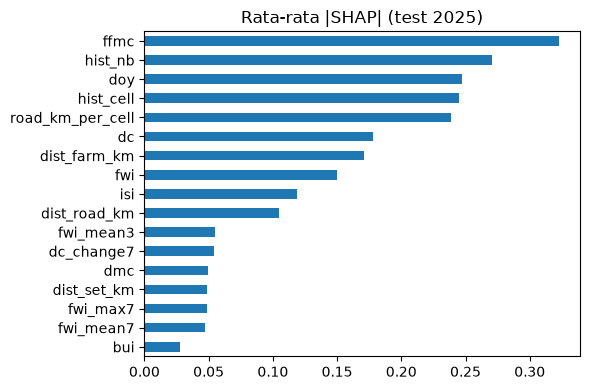

,semua sel (%),top 1% risiko (%)
cuaca,54.6,39.6
manusia,23.7,16.5
histori,21.7,43.9


In [16]:
# SHAP (LightGBM's built-in TreeSHAP): which features — and which group — drive the risk?
sample = test_a.sample(200_000, random_state=0)
contrib = pd.DataFrame(model_a.booster_.predict(sample[FEATURES], pred_contrib=True)[:, :-1], columns=FEATURES)
contrib.abs().mean().sort_values().plot.barh(figsize=(6, 4), title="Rata-rata |SHAP| (test 2025)")
plt.tight_layout(); plt.show()


def group_share(c):
    g = pd.Series({k: c[v].abs().sum(axis=1).mean() for k, v in GROUPS.items()})
    return (100 * g / g.sum()).round(1)


p = model_a.predict_proba(sample[FEATURES])[:, 1]
top = p >= np.quantile(p, 0.99)
pd.DataFrame({"semua sel (%)": group_share(contrib), "top 1% risiko (%)": group_share(contrib[top])})

# Tahap 4 — Output: peta risiko
Probabilitas → skor 0–1 → kelas **rendah / sedang / tinggi / ekstrem** (ambang dashboard 0.30 / 0.55 / 0.75). Minggu 27 Jul – 2 Agu 2021 diekspor ke `dashboard/data.json` memakai model hindcast (2021 tidak dilihat saat training).

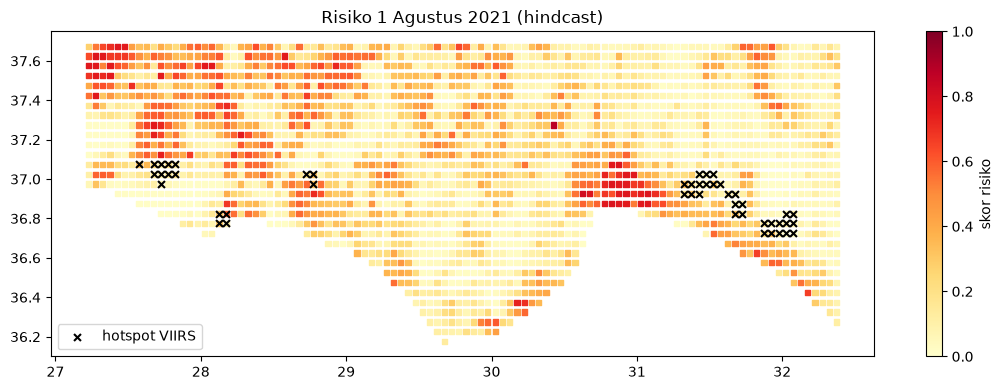

In [17]:
# Risk classes: raw probabilities are tiny (base rate ~0.1%), so map them to the dashboard's 0-1 score
# by quantile: top 20% -> sedang (>=0.30), top 5% -> tinggi (>=0.55), top 1% -> ekstrem (>=0.75)
CLASSES = ["rendah", "sedang", "tinggi", "ekstrem"]
season = test_b[test_b.date.dt.month.between(6, 9)]
pb = model_b.predict_proba(season[FEATURES])[:, 1]
CUTS = {"probs": np.quantile(pb, [0, 0.80, 0.95, 0.99, 1]).tolist(), "scores": [0, 0.30, 0.55, 0.75, 1]}
to_score = lambda prob: np.interp(prob, CUTS["probs"], CUTS["scores"])

(ROOT / "models").mkdir(exist_ok=True)
joblib.dump({"model": model_a, "model_hindcast_2021": model_b, "features": FEATURES,
             "groups": GROUPS, "risk_cuts": CUTS}, ROOT / "models/fire_lgbm.joblib")

# map for 1 Aug 2021 with the real VIIRS hotspots of that day
d1 = test_b[test_b.date == "2021-08-01"].copy()
d1["score"] = to_score(model_b.predict_proba(d1[FEATURES])[:, 1])
fig, ax = plt.subplots(figsize=(11, 4))
sc = ax.scatter(d1.lon_c, d1.lat_c, c=d1.score, cmap="YlOrRd", vmin=0, vmax=1, marker="s", s=14)
f1 = d1[d1.y == 1]
ax.scatter(f1.lon_c, f1.lat_c, marker="x", c="k", s=25, label="hotspot VIIRS")
ax.set_title("Risiko 1 Agustus 2021 (hindcast)"); ax.legend(); plt.colorbar(sc, label="skor risiko")
plt.tight_layout(); plt.show()

In [18]:
# Export 27 Jul – 2 Aug 2021 (hindcast) to the dashboard; the demo file is kept as data.demo.json
days = pd.date_range("2021-07-27", "2021-08-02")
week = test_b[test_b.date.isin(days)].copy()
week["score"] = to_score(model_b.predict_proba(week[FEATURES])[:, 1])

dash_path = ROOT / "bizdenbize/dashboard/data.json"
backup = dash_path.with_name("data.demo.json")
if not backup.exists():
    shutil.copy(dash_path, backup)
dash = json.loads(backup.read_text(encoding="utf-8"))
order = pd.DataFrame({"ix": dash["cells"]["ix"], "iy": dash["cells"]["iy"]})
st = order.merge(static, on=["ix", "iy"], how="left")
dash["cells"]["dist_road"] = st.dist_road_km.round(1).tolist()
dash["cells"]["dist_set"] = st.dist_set_km.round(1).tolist()
fwi_days, risk_days = [], []
for day in days:
    w = order.merge(week[week.date == day], on=["ix", "iy"], how="left")
    fwi_days.append(w.fwi.round(1).fillna(0).tolist())
    risk_days.append(w.score.round(3).fillna(0).tolist())
dash["cells"]["fwi"], dash["cells"]["risk"] = fwi_days, risk_days
dash["meta"]["demo"] = False
dash["meta"]["note"] = ("FWI: Copernicus CEMS/EFFIS. Risiko: LightGBM dilatih pada 2022-2025 (hindcast, 2021 tidak "
                        "dilihat model). Jarak jalan/permukiman: OpenStreetMap. Label: EFFIS hotspot VIIRS. "
                        "Elevasi, lereng & tutupan lahan masih DEMO.")
dash_path.write_text(json.dumps(dash, separators=(",", ":")), encoding="utf-8")

# did the real fires that week land in high classes?
fires = week[week.y == 1]
print("sel-hari terbakar minggu itu:", len(fires))
print(pd.cut(fires.score, [-1, 0.30, 0.55, 0.75, 2], labels=CLASSES).value_counts().sort_index())

sel-hari terbakar minggu itu: 235
score
rendah     146
sedang      79
tinggi       8
ekstrem      2
Name: count, dtype: int64


In [ ]:
# Real OSM overlays for the dashboard map (replacing the demo polylines / town list):
# major roads merged + simplified to ~300 m so data.json stays small, and cities/towns with OSM population
bbox_poly = box(LON0, LAT0, LON1, LAT1)
roads = gpd.read_file(DATA / "osm_roads.gpkg")
roads = roads[roads.fclass.isin(["motorway", "trunk", "primary"])].clip(bbox_poly)
merged = shapely.line_merge(shapely.union_all(roads.geometry.values))
lines = gpd.GeoSeries([merged], crs=4326).explode(index_parts=False).to_crs(3035).simplify(300).to_crs(4326)
dash["roads"] = [[[round(x, 3), round(y, 3)] for x, y in g.coords] for g in lines if len(g.coords) > 1]

towns = gpd.read_file(f"zip://{ZIP}!gis_osm_places_free_1.shp", bbox=(LON0, LAT0, LON1, LAT1),
                      where="fclass IN ('city','town')")
towns = towns.sort_values("population", ascending=False)
dash["settlements"] = [[n, round(g.x, 3), round(g.y, 3), int(p or 0)]
                       for n, g, p in zip(towns.name, towns.geometry, towns.population.fillna(0))]
dash_path.write_text(json.dumps(dash, separators=(",", ":")), encoding="utf-8")
print("jalan:", len(dash["roads"]), "garis | permukiman:", len(dash["settlements"]),
      "| data.json:", dash_path.stat().st_size // 1024, "KB")

## Langkah berikutnya
- **Lingkungan statis**: tambahkan lereng (SRTM) dan tutupan lahan (CORINE) — terutama hutan *Pinus brutia* — sebagai grup `lingkungan`.
- **Masker darat**: ganti garis pantai skematik di `data.json` dengan poligon daratan asli (mis. OSM `water`/coastline).
- **Spatial block CV** sebagai pelengkap split temporal.
- **Dashboard**: teks UI di `dashboard/app.js` masih menyebut "demo"; perbarui setelah hasil final.
- **Catatan data**: EWDS menghentikan pembaruan `cems-fire-historical-v1` mulai 16 Nov 2026 (rekonfigurasi MARS) — data historis tetap bisa diunduh.